<a href="https://colab.research.google.com/github/natenorris10/MAT-422/blob/main/HW_3_4.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

#Homework 3.4 - Calculus and Optimization

In [23]:
import numpy as np
import matplotlib.pyplot as plt

from sklearn.datasets import make_moons
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, confusion_matrix

###3.4 - Logistic Regression

Logistic regression is a method of modeling the binary classification of a dependent variable.  It can be used to classify more than just a binary options, but in the further examples will just be used for classifying 0 or 1.

Let matrix $A \in \mathbb{R}^{n \times d}$ have rows $\mathbf{α}_j^T, j=1,...,n,$ which represent the features, and $\mathbf{b}=(b_1,...,b_n)^T \in \{0, 1\}^n,$ which represent the classification.  To find a function of the features that approximates the probability of being classified as 1, we use the logit function to model the probability of being classified as 1 as a linear function of the features.

For $\mathbf{x}, \mathbf{α} \in \mathbb{R}^d$ let $p(\mathbf{α}; \mathbf{x})$ be the probability of the result to be $1.$  Then we can define the logit function <br>
$log \dfrac{p(\mathbf{α}; \mathbf{x})}{1 - p(\mathbf{α}; \mathbf{x})} = \mathbf{α}^T \mathbf{x}$ <br>
This can then be rearranged as $p(\mathbf{α};\mathbf{x}) = σ(\mathbf{α}^T \mathbf{x}),$ where $σ = \dfrac{1}{1 + e^{-t}}, \space t \in \mathbb{R},$ is the sigmoid function.

In [10]:
# The sigmoid function
def sigmoid(t):
  return 1 / (1 + np.exp(-t))

tvals = np.linspace(-5, 5, 200)

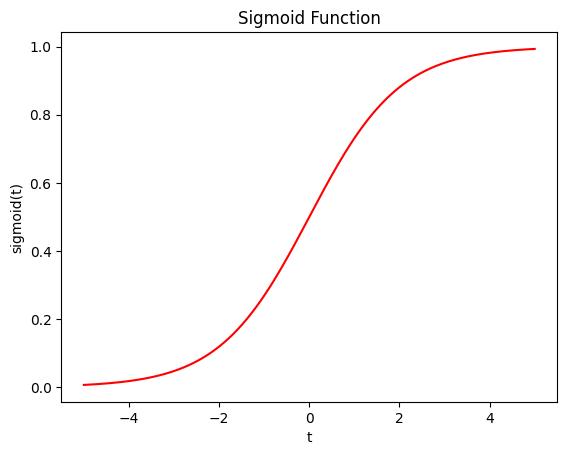

In [29]:
# Plotting sigmoid, which takes real numbers and maps them to probabilities

plt.plot(tvals, sigmoid(tvals), color="red")
plt.xlabel("t")
plt.ylabel("sigmoid(t)")
plt.title("Sigmoid Function")
plt.show()

In [21]:
# Logit function
def logit(p):
  return np.log(p / (1 - p))

pvals = np.linspace(0, 1, 200)

/tmp/ipykernel_1152/3778542132.py:3: RuntimeWarning: divide by zero encountered in divide
  return np.log(p / (1 - p))
/tmp/ipykernel_1152/3778542132.py:3: RuntimeWarning: divide by zero encountered in log
  return np.log(p / (1 - p))


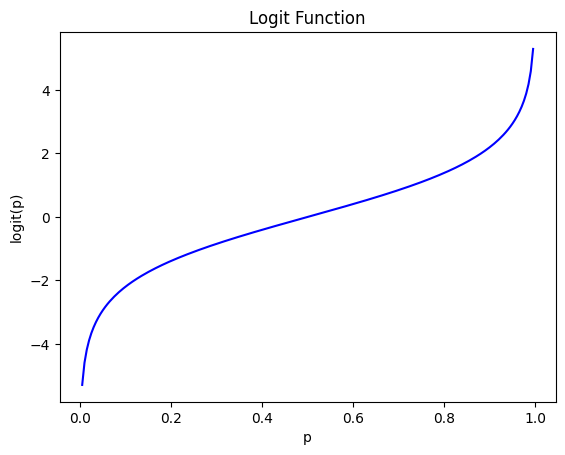

In [30]:
# Plotting logit, which takes probabilities and maps them onto real number line

plt.plot(pvals, logit(pvals), color="blue")
plt.xlabel("p")
plt.ylabel("logit(p)")
plt.title("Logit Function")
plt.show()

###Binary Classification

Below is an example of a basic binary classification using logistic regression on the make_moons toy dataset from scikit-learn.  This dataset isn't the best to use for a linear classification, but it's fun just to see.

In [25]:
X, y = make_moons(n_samples=200, noise=0.2, random_state=10)

model = LogisticRegression()
model.fit(X, y)
pred = model.predict(X)
proba = model.predict_proba(X)[:, 1]

print("Coefficients: ", model.coef_)
print("Intercept: ", model.intercept_)
print("Training accuracy: ", accuracy_score(y, pred))
print("Confusion matrix:")
print(confusion_matrix(y, pred))

Coefficients:  [[ 1.15539424 -3.30573881]]
Intercept:  [0.3529516]
Training accuracy:  0.865
Confusion matrix:
[[88 12]
 [15 85]]


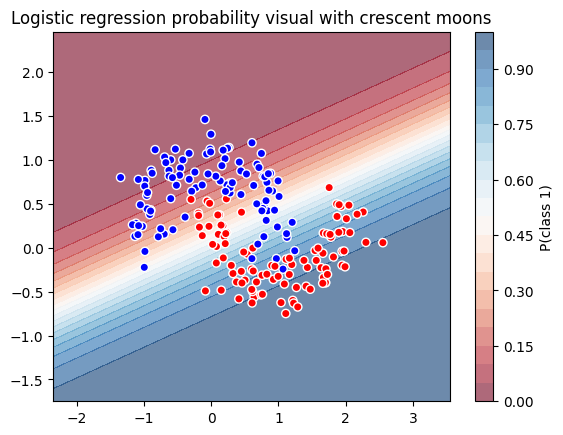

In [28]:
xx, yy = np.meshgrid(np.linspace(X[:,0].min() - 1, X[:,0].max() + 1, 150),
                     np.linspace(X[:,1].min() - 1, X[:,1].max() + 1, 150))

grid = np.c_[xx.ravel(), yy.ravel()]
zz = model.predict_proba(grid)[:, 1].reshape(xx.shape)

plt.contourf(xx, yy, zz, levels=20, cmap="RdBu", alpha=0.6)
plt.colorbar(label="P(class 1)")
plt.scatter(X[:,0], X[:,1], c=y, edgecolor="white", cmap="bwr")
plt.title("Logistic regression probability visual with crescent moons")
plt.show()

The above plot gives a visual representation of how our linear logistic regression model fit the data.  The colorbar shows if something was classified as class 1 (blue shaded area) or class 0 (red shaded area).  Again, since our data follows a particular crescent moon pattern, the linearity of a logistic regression classifier isn't the best method to use.  But, it's still an interesting experiment to try out.